In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt

df = pd.read_csv("../data/forest+fires/forestfires.csv", delimiter=",")
print("Shape: ", df.shape)
df.info()
print(df.describe(include="all").T)
print(df.isna().mean().sort_values(ascending=False))
print(df.nunique().sort_values())
print(df[df.duplicated()])
print("Duplicates: ", df.duplicated().sum())


Shape:  (517, 13)
<class 'pandas.DataFrame'>
RangeIndex: 517 entries, 0 to 516
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X       517 non-null    int64  
 1   Y       517 non-null    int64  
 2   month   517 non-null    str    
 3   day     517 non-null    str    
 4   FFMC    517 non-null    float64
 5   DMC     517 non-null    float64
 6   DC      517 non-null    float64
 7   ISI     517 non-null    float64
 8   temp    517 non-null    float64
 9   RH      517 non-null    int64  
 10  wind    517 non-null    float64
 11  rain    517 non-null    float64
 12  area    517 non-null    float64
dtypes: float64(8), int64(3), str(2)
memory usage: 52.6 KB
       count unique  top freq        mean         std   min    25%    50%  \
X      517.0    NaN  NaN  NaN    4.669246    2.313778   1.0    3.0    4.0   
Y      517.0    NaN  NaN  NaN    4.299807      1.2299   2.0    4.0    4.0   
month    517     12  aug  184         NaN  

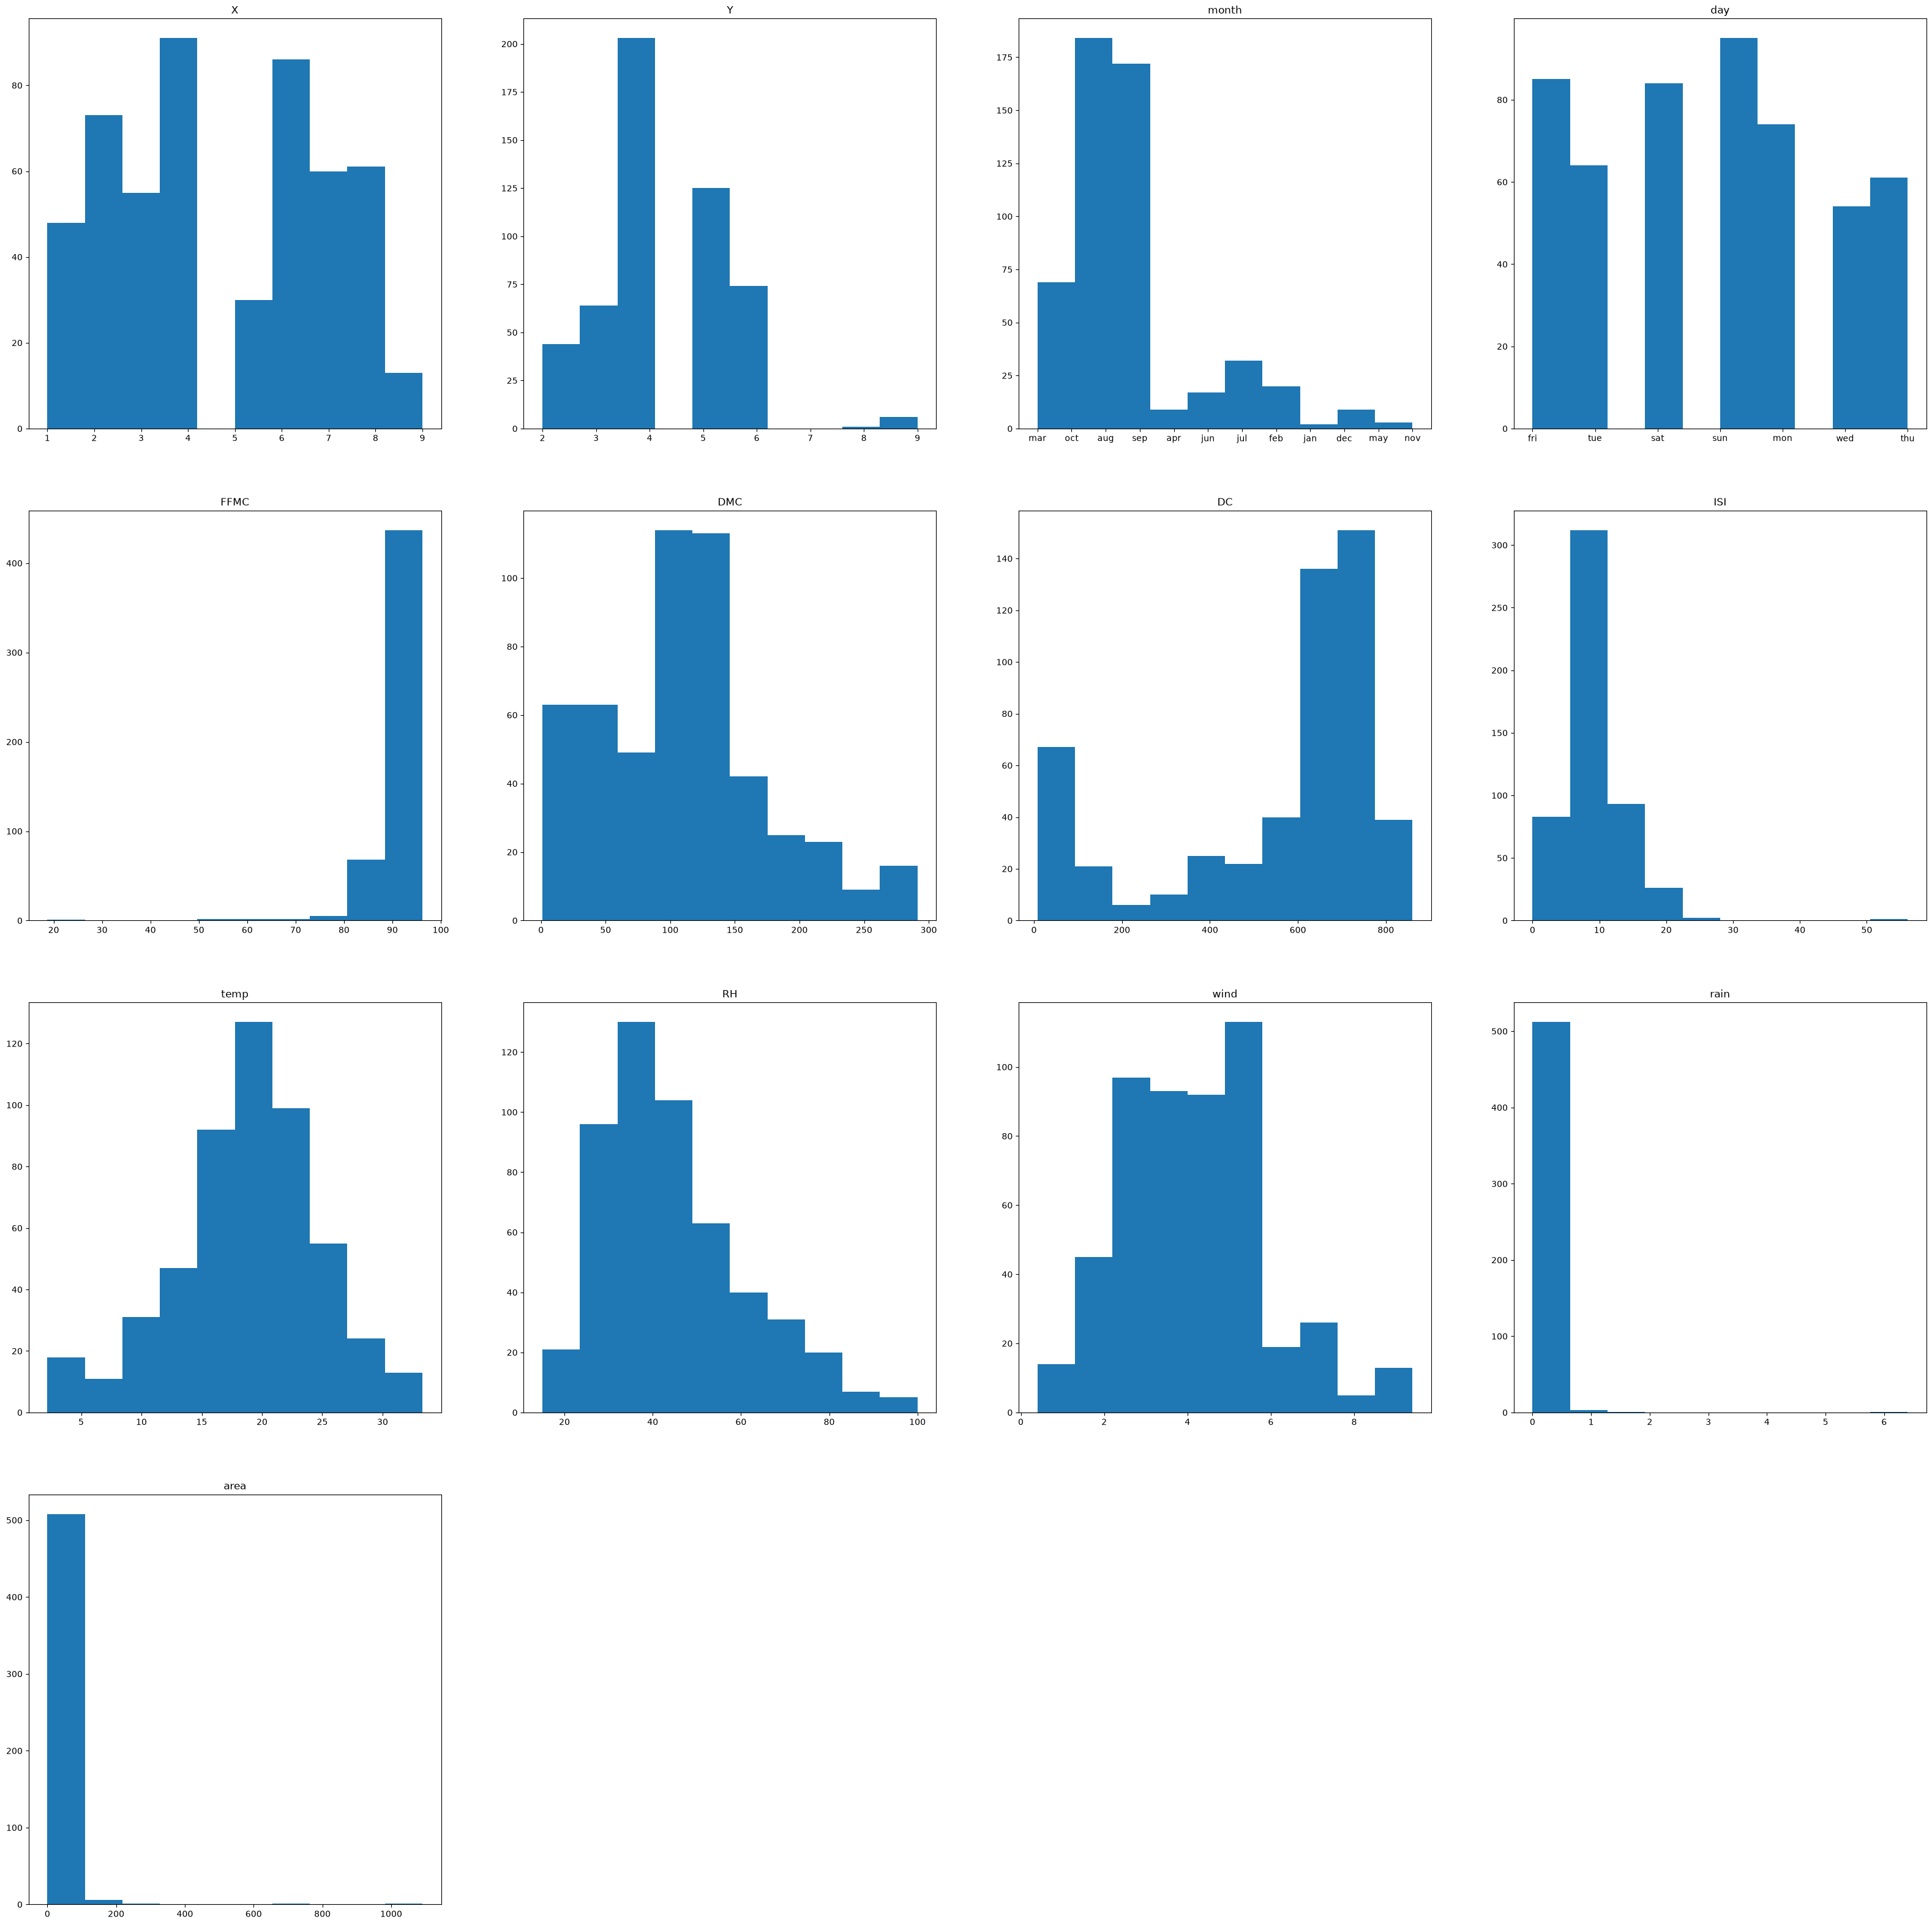

In [11]:
#GET THE DISTRIBUTIONS OF ALL FEATURES
i = 1
plt.figure(figsize=(40,40))
for feature in df:
    plt.subplot(4,4,i, title = feature).hist(df[feature])
    i+=1

Discard days, the day of the week isn't relevant to the area burned by a forest fire.

Possibly discard months, as they are used to determine the DMC and DC scores. Therefore, their relevance is already accounted for.

Getting BUI and FWI could possibly allow in removing some of the other columns.

Normalise the target (area) as it is very skewed towards 0.

Rain is also very skewed towards 0 so it may need to be normalised as well.

Remove 4 duplicates.

Figure out most influential subset of data

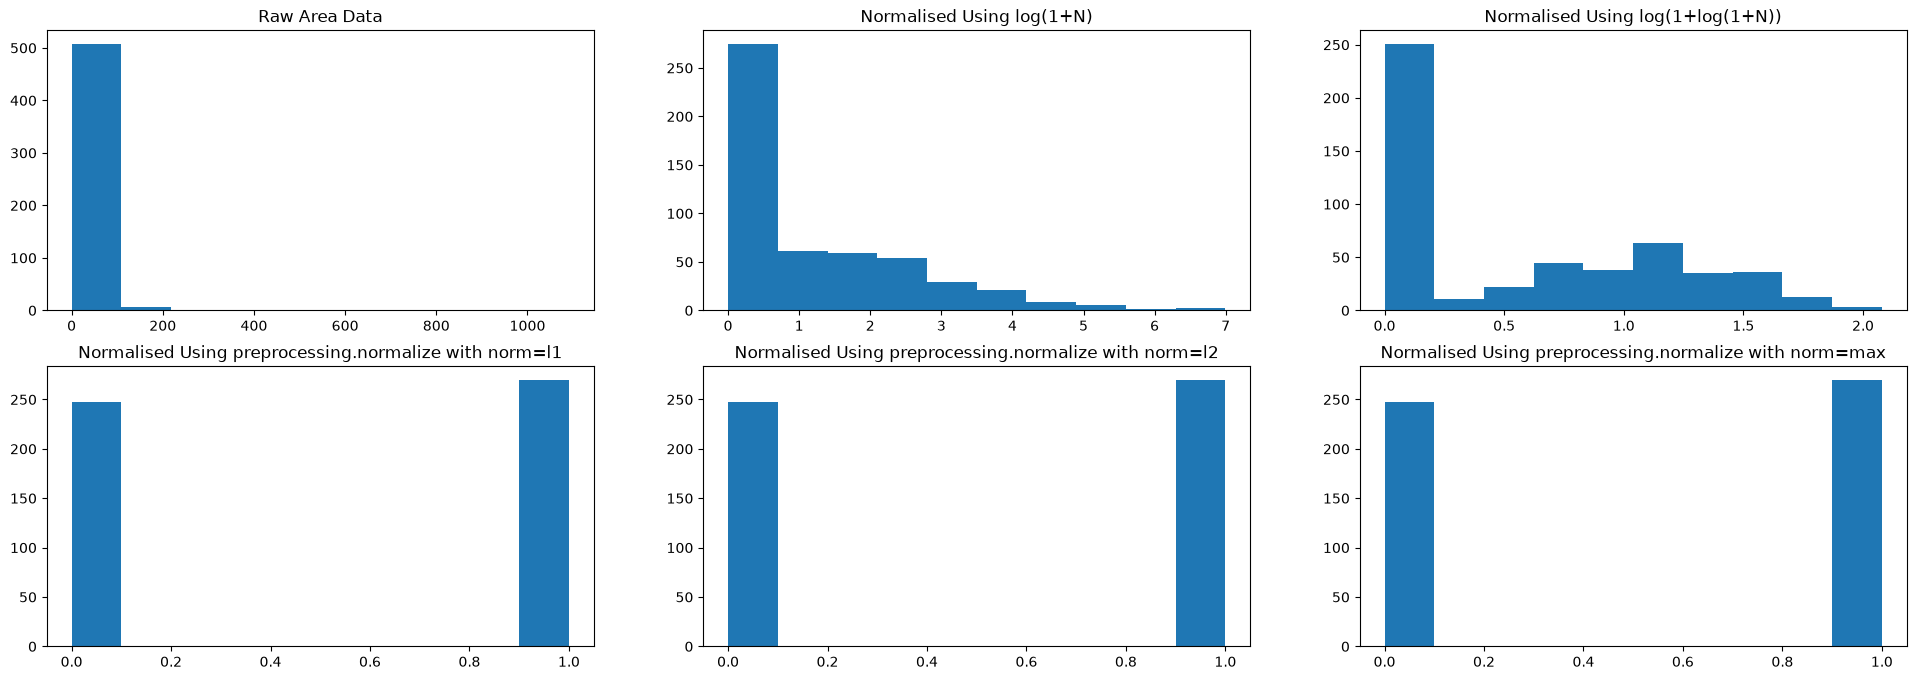

In [36]:
from sklearn import preprocessing
# Trying some normalisation for area
plt.figure(figsize=(24,8))

plt.subplot(231, title = "Raw Area Data").hist(df["area"])

plt.subplot(232, title = "Normalised Using log(1+N)").hist(np.log1p(df["area"]))

plt.subplot(233, title = "Normalised Using log(1+log(1+N))").hist(np.log1p(np.log1p(df["area"])))

plt.subplot(234, title = "Normalised Using preprocessing.normalize with norm=l1").hist(preprocessing.normalize(df[["area"]], norm='l1'))
plt.subplot(235, title = "Normalised Using preprocessing.normalize with norm=l2").hist(preprocessing.normalize(df[["area"]], norm='l2'))
plt.subplot(236, title = "Normalised Using preprocessing.normalize with norm=max").hist(preprocessing.normalize(df[["area"]], norm='max'))

plt.show()